###  CSCI 538 - Assignment 04


Submitted by:Nagashree Herambapura Nagaraja <br>
CWID: 50434952


#### Question 1 - Minimum Edit Distance Algorithm

In this question, I use the Minimum Edit Distance algorithm to compare my first name with a list of words that begin with the same letter.

The goal is to find the word that is most similar to my first name based on the minimum number of edit operations needed to change one string into another.

My first name is "nagashree" and I selected the ten words beginning with the letter "n" from words.txt then used the given EditDistance.py program to compare my name with those words and find the most similar word.


<br>
1(a) - Find the most similar word:

The ten words beginning with "n" are: nadir, nascent, nefarious, nemesis, neophyte, nettle, nocturnal, noisome, nonplussed, nuance

I used the given minimum distance program with my first name and these ten words.

In [22]:
import numpy as np

def min_edit_distance(word1, word2):
    m = len(word1)
    n = len(word2)
    D = np.zeros((m + 1, n + 1))

    for i in range(m + 1):
        D[i][0] = i

    for j in range(n + 1):
        D[0][j] = j

    for i in range(1, m + 1):
        for j in range(1, n + 1):
            if word1[i - 1] == word2[j - 1]:
                cost = 0
            else:
                cost = 1

            D[i][j] = min(
                D[i - 1][j] + 1,
                D[i][j - 1] + 1,
                D[i - 1][j - 1] + cost
            )

    return int(D[m][n])


def find_similar_word(word, word_list):
    min_distance = float('inf')
    similar_word = ''

    for w in word_list:
        distance = min_edit_distance(word, w)

        if distance < min_distance:
            min_distance = distance
            similar_word = w

    return similar_word


# Ten words beginning with N from words.txt
word_list = ['nadir','nascent','nefarious','nemesis','neophyte','nettle', 'nocturnal','noisome','nonplussed','nuance']


# My first name
firstname = 'nagashree'

similar_word = find_similar_word(firstname, word_list)

print("Your first name is:", firstname)
print("The most similar word is:", similar_word)
print(f"The most similar word to '{firstname}' is '{similar_word}'")

Your first name is: nagashree
The most similar word is: nadir
The most similar word to 'nagashree' is 'nadir'


<br>
1(b) Output:

The program compares my name with each word and returns the word with the smallest edit distance.

The output shows that the most similar word is "nadir"

<br>

#### Question 2 - Q-Learning with MoutainCar

2 (a) - MoutainCar-v0 Environmnet:
In this part, I will create the Moutaincar-v0 environment and display the observation space, action space and initial state.And then I'll explain what the state values and actions represent.

In [23]:
%pip install gymnasium numpy matplotlib pygame

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [24]:
import gymnasium as gym
import numpy as np
import matplotlib.pyplot as plt
import pickle

def run(episodes, is_training=True, render=False):

    # Creating the MountainCar-v0 environment
    env = gym.make(
        'MountainCar-v0',
        render_mode='human' if render else None
    )

    # Reset the environment and get the initial state
    state = env.reset(seed=42)[0]

    # Display the observation space
    print("Observation space:", env.observation_space)

    # Display the available actions
    print("Action space:", env.action_space)

    # Display the starting state
    print(f"Initial state: [{state[0]:.4f}, {state[1]:.4f}]")

    # Show the range of the state variables
    print("\nState values:")
    print(
        "Position range:",
        env.observation_space.low[0],
        "to",
        env.observation_space.high[0]
    )

    print(
        "Velocity range:",
        env.observation_space.low[1],
        "to",
        env.observation_space.high[1]
    )

    # Explain the three possible actions
    print("\nActions:")
    print("0 = Push left")
    print("1 = No acceleration")
    print("2 = Push right")

    env.close()


if __name__ == '__main__':
    run(1, is_training=False, render=False)

Observation space: Box([-1.2  -0.07], [0.6  0.07], (2,), float32)
Action space: Discrete(3)
Initial state: [-0.4452, 0.0000]

State values:
Position range: -1.2 to 0.6
Velocity range: -0.07 to 0.07

Actions:
0 = Push left
1 = No acceleration
2 = Push right


2 (a) : Explanation:

The MountainCar-v0 state contains two values: Position and Velocity.
(i) The position tells where the car is located on the hill.
(ii) The velocity tells how fast the car is moving and in which direction.

The position ranges from -1.2 to 0.6, while the velocity ranges from -0.07 to 0.07.

The environment has three possible actions:
(i) 0 means pushing the car to the left
(ii) 1 means no acceleration
(iii) 2 means pushing the car to the right

The goal of the agent is to learn how to build enough momentum to reach the top of the hill on the right side.




 <br>
 2 (b) - State Discretization and Q-Table

 The last digit of my CWID is 2, so I use 20 + 2 = 22 equally spaced boundaries for both position and velocity.

 Since moutaincar-v0 has continous state values, I discretize the position and velocity before applying tabular Q-learning. I also create a Q-table that can store Q-values for every discrete state and all three actions.

In [25]:
import gymnasium as gym
import numpy as np

# Create the MountainCar-v0 environment
env = gym.make('MountainCar-v0')

# Reset the environment
state = env.reset(seed=42)[0]

# Last digit of my CWID
X = 2

# Number of boundaries required
num_boundaries = 20 + X

# Create equally spaced boundaries for position and velocity
pos_space = np.linspace(
    env.observation_space.low[0],
    env.observation_space.high[0],
    num_boundaries
)

vel_space = np.linspace(
    env.observation_space.low[1],
    env.observation_space.high[1],
    num_boundaries
)

# Convert the initial continuous state into discrete indices
state_p = np.digitize(state[0], pos_space)
state_v = np.digitize(state[1], vel_space)

# np.digitize can return an index from 0 through len(boundaries)
# So one extra row and column are needed in the Q-table
q = np.zeros(
    (
        len(pos_space) + 1,
        len(vel_space) + 1,
        env.action_space.n
    )
)

print("Last CWID digit (X):", X)
print("Number of boundaries:", num_boundaries)

print("\nPosition boundaries:")
print(pos_space)

print("\nVelocity boundaries:")
print(vel_space)

print("\nInitial continuous state:")
print(f"[{state[0]:.4f}, {state[1]:.4f}]")

print("\nInitial discrete state:")
print("Position index:", state_p)
print("Velocity index:", state_v)

print("\nQ-table shape:")
print(q.shape)

print("\nTotal Q-table entries:")
print(q.size)

print("\nEpsilon-greedy action selection:")
print("If a random value is less than epsilon, choose a random action.")
print("Otherwise, choose the action with the highest Q-value.")

env.close()

Last CWID digit (X): 2
Number of boundaries: 22

Position boundaries:
[-1.2        -1.1142857  -1.0285715  -0.94285715 -0.8571429  -0.7714286
 -0.6857143  -0.6        -0.51428574 -0.42857146 -0.34285718 -0.2571429
 -0.17142856 -0.08571434  0.          0.08571422  0.17142856  0.2571429
  0.34285712  0.42857146  0.5142857   0.6       ]

Velocity boundaries:
[-0.07       -0.06333333 -0.05666666 -0.05       -0.04333333 -0.03666667
 -0.03       -0.02333333 -0.01666667 -0.01       -0.00333333  0.00333334
  0.01        0.01666667  0.02333333  0.03        0.03666667  0.04333334
  0.05        0.05666666  0.06333334  0.07      ]

Initial continuous state:
[-0.4452, 0.0000]

Initial discrete state:
Position index: 9
Velocity index: 11

Q-table shape:
(23, 23, 3)

Total Q-table entries:
1587

Epsilon-greedy action selection:
If a random value is less than epsilon, choose a random action.
Otherwise, choose the action with the highest Q-value.


2(b) - Explanation:
The last didgit of my CWID is 2, So I used 22 equally spaced boundaries for both position and velocity.

Since the MountainCar state has continuous values, I converted theposition and velocity into discrete indices using np.digitize().Because np.digitize() can return an index equal to the number of boundaries. I created the Q-table with one extra position and velocity index. Therefore, the Q-table shape is (23,23,3).

The last dimension has size 3 because MountainCar-v0 has three possible actions.

For epsilon-greedy action selection the agent chooses a random action when a random value is less than epsilon. Otherwise, it chooses the action with the highest Q-value for the current state. This allows the agent to explore different actions while gradually using what it has learned.


2 (c) - Q-Learning Training:

For this part, I will train the MountainCar agent for 5000 episodes using Q-Learning.

I use the epsilon-greedy strategy for training so that the agent can explore different actions at the beginning and gradually use the learned Q-values further.

Then I calculate the moving average reward over the most recent 100 episodes and display one example of Q-value update from a nonterminal transition.

In [26]:
import gymnasium as gym
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# Last digit of my CWID
X = 2

# Number of boundaries
num_boundaries = 20 + X

# Create MountainCar environment
env = gym.make("MountainCar-v0")

# Position discretization
pos_space = np.linspace(
    env.observation_space.low[0],
    env.observation_space.high[0],
    num_boundaries
)

# Velocity discretization
vel_space = np.linspace(
    env.observation_space.low[1],
    env.observation_space.high[1],
    num_boundaries
)

# Initialize Q-table
q = np.zeros((
    len(pos_space) + 1,
    len(vel_space) + 1,
    env.action_space.n
))

# Q-learning parameters
alpha = 0.9
gamma = 0.9
epsilon = 1.0
epsilon_decay = 2 / 5000

# Random seed
rng = np.random.default_rng(42)

episodes = 5000
rewards_per_episode = np.zeros(episodes)
epsilon_values = []

# Show one Q-learning update
transition_saved = False

for episode in range(episodes):

    # Reset the environment
    state, _ = env.reset(seed=42 + episode)

    # Discretize initial state
    state_p = np.digitize(state[0], pos_space)
    state_v = np.digitize(state[1], vel_space)

    terminated = False
    truncated = False
    total_reward = 0

    epsilon_values.append(epsilon)

    # Stop if goal is reached or time limit is reached
    while not terminated and not truncated:

        # Epsilon-greedy action selection
        if rng.random() < epsilon:
            action = int(
                rng.integers(0, env.action_space.n)
            )
        else:
            action = int(
                np.argmax(q[state_p, state_v, :])
            )

        # Execute action
        new_state, reward, terminated, truncated, _ = env.step(
            action
        )

        # Discretize next state
        new_state_p = np.digitize(
            new_state[0], pos_space
        )
        new_state_v = np.digitize(
            new_state[1], vel_space
        )

        # Current Q-value
        current_q = q[state_p, state_v, action]

        # Q-learning target
        # Bootstrap on truncation, not termination
        if terminated:
            max_next_q = 0.0
            target = reward
        else:
            max_next_q = np.max(
                q[new_state_p, new_state_v, :]
            )
            target = reward + gamma * max_next_q

        # Update Q-value
        new_q = current_q + alpha * (
            target - current_q
        )

        q[state_p, state_v, action] = new_q

        # Display one nonterminal Q-learning update
        if (
            not transition_saved
            and not terminated
            and not truncated
        ):
            print("Example Q-learning update")
            print("-------------------------")
            print(
                "Current state indices:",
                (int(state_p), int(state_v))
            )
            print("Action:", action)
            print("Reward:", reward)
            print(
                "Next state indices:",
                (int(new_state_p), int(new_state_v))
            )
            print("Current Q-value:", current_q)
            print(
                "Maximum next-state Q-value:",
                max_next_q
            )
            print("Updated Q-value:", new_q)

            transition_saved = True

        # Move to next state
        state_p = new_state_p
        state_v = new_state_v

        total_reward += reward

    # Store episode reward
    rewards_per_episode[episode] = total_reward

    # Reduce exploration
    epsilon = max(epsilon - epsilon_decay, 0)

env.close()

print("\nTraining completed!")
print("Total episodes:", episodes)
print("Q-table shape:", q.shape)
print(
    "Average reward (last 100):",
    round(np.mean(rewards_per_episode[-100:]), 2)
)



Example Q-learning update
-------------------------
Current state indices: (9, 11)
Action: 1
Reward: -1.0
Next state indices: (9, 11)
Current Q-value: 0.0
Maximum next-state Q-value: 0.0
Updated Q-value: -0.9

Training completed!
Total episodes: 5000
Q-table shape: (23, 23, 3)
Average reward (last 100): -175.38


In [27]:
print("Best episode reward:", np.max(rewards_per_episode))

print(
    "Number of episodes that finished before -200:",
    np.sum(rewards_per_episode > -200)
)

print(
    "Last 10 episode rewards:",
    rewards_per_episode[-10:]
)

Best episode reward: -161.0
Number of episodes that finished before -200: 1650
Last 10 episode rewards: [-180. -170. -174. -176. -178. -180. -181. -172. -175. -168.]


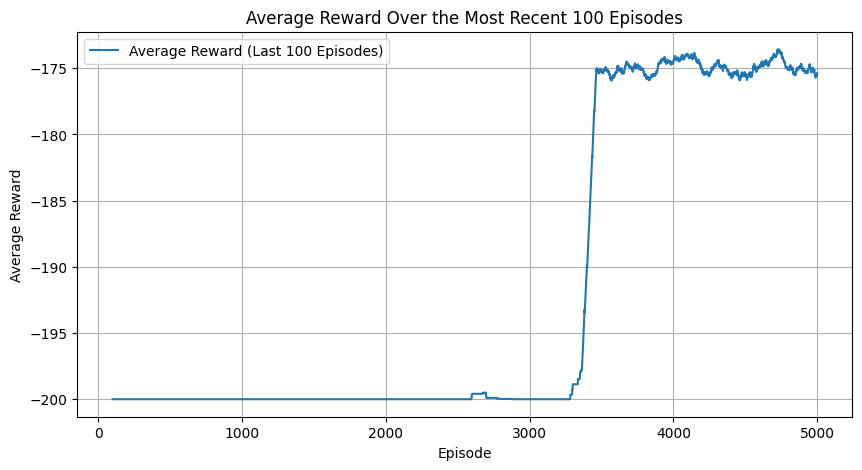

In [28]:

# Calculate the moving average reward
window = 100

moving_avg = np.convolve(
    rewards_per_episode,
    np.ones(window) / window,
    mode="valid"
)

plt.figure(figsize=(10, 5))

plt.plot(
    np.arange(window, episodes + 1),
    moving_avg,
    label="Average Reward (Last 100 Episodes)"
)

plt.title("Average Reward Over the Most Recent 100 Episodes")
plt.xlabel("Episode")
plt.ylabel("Average Reward")
plt.legend()
plt.grid(True)
plt.show()


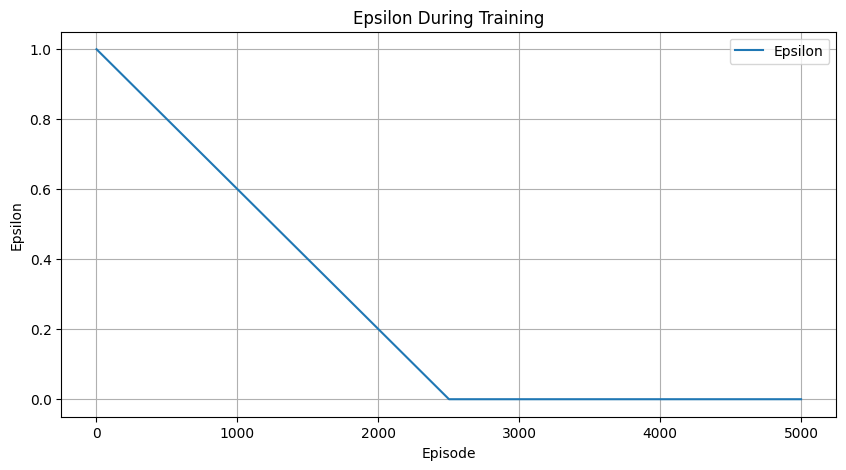

In [29]:
plt.figure(figsize=(10, 5))

plt.plot(
    range(1, episodes + 1),
    epsilon_values,
    label="Epsilon"
)

plt.title("Epsilon During Training")
plt.xlabel("Episode")
plt.ylabel("Epsilon")
plt.legend()
plt.grid(True)
plt.show()


2(c) Explanation:
I trained the MountainCar agent for 5,000 episodes using Q-learning. At first, the average reward stayed close to -200 because the agent was unable to reach the goal within the time limit.

After around 3,300 episodes, I noticed that the average reward started improving and later reached around -175. This shows that the agent gradually learned to reach the goal in fewer steps.

I used the average reward from the most recent 100 episodes instead of looking at only one episode at a time.This made the learning pattern easier to understand,because individual rewards can change from one episode to another.

For one nonterminal transition, the current state index was (9,11) and the agent selected action 1. The reward was - 1.0 and the next state was also (9,11). The current Q-value abd the maximum Q-value of the next state were both 0.0

Using the Q-learning formula, 
Q_{t+1}(s_{t}, a_{t}) = Q_{t}(s_{t}, a_{t}) + α [ R_{t+1} + γ · maxₐ Q_{t} (s_{t+1} , a) – Q_{t}(s_{t}, a_{t}) ] <br>

For this transition:
Q_{t}(s_{t}, a_{t}) = 0 <br>
R_{t+1} = -1  <br>
maxₐ Q_{t} (s_{t+1} , a) = 0 <br>
α = 0.9 , γ = 0.9  <br>

Substituting these values in the above formula:
Q_{t+1}(s_{t}, a_{t}) = 0 + 0.9 [ -1 + 0.9 * 0 - 0] = -0.9

So, the Q-value was updated from 0.0 to -0.9



<br>
2(d) - Evaluation and Learning rate Comparison:

In this part,I evaluate the trained agent for 100 episodes without exploration and without updating the Q-table. Here, the average total reward and the number of times the agent reaches the goal will be reported. And then the results of two learning rates will be comapared, that is alpha = 0.1 and alpha = 0.9, while keeping the other setting the same.

In [30]:
def evaluate_agent(q_table, episodes=100, seed_start=1000):

    eval_env = gym.make('MountainCar-v0')

    total_rewards = []
    success_count = 0

    for episode in range(episodes):

        # Start a new evaluation episode
        state = eval_env.reset(seed=seed_start + episode)[0]

        state_p = np.digitize(state[0], pos_space)
        state_v = np.digitize(state[1], vel_space)

        terminated = False
        truncated = False
        total_reward = 0

        while not terminated and not truncated:

            # No exploration during evaluation
            # Always use the action with the highest Q-value
            action = int(
                np.argmax(q_table[state_p, state_v, :])
            )

            new_state, reward, terminated, truncated, _ = eval_env.step(action)

            new_state_p = np.digitize(new_state[0], pos_space)
            new_state_v = np.digitize(new_state[1], vel_space)

            total_reward += reward

            state_p = new_state_p
            state_v = new_state_v

        # Save the total reward for this episode
        total_rewards.append(total_reward)

        # Count the episode as successful if the goal was reached
        if terminated:
            success_count += 1

    eval_env.close()

    average_reward = np.mean(total_rewards)

    return average_reward, success_count, total_rewards

In [31]:
avg_reward_09, success_09, rewards_09 = evaluate_agent(q)

print("Evaluation for alpha = 0.9")
print("Average total reward:", avg_reward_09)
print("Goals reached:", success_09, "out of 100")
print("Success rate:", success_09, "%")

Evaluation for alpha = 0.9
Average total reward: -175.59
Goals reached: 100 out of 100
Success rate: 100 %


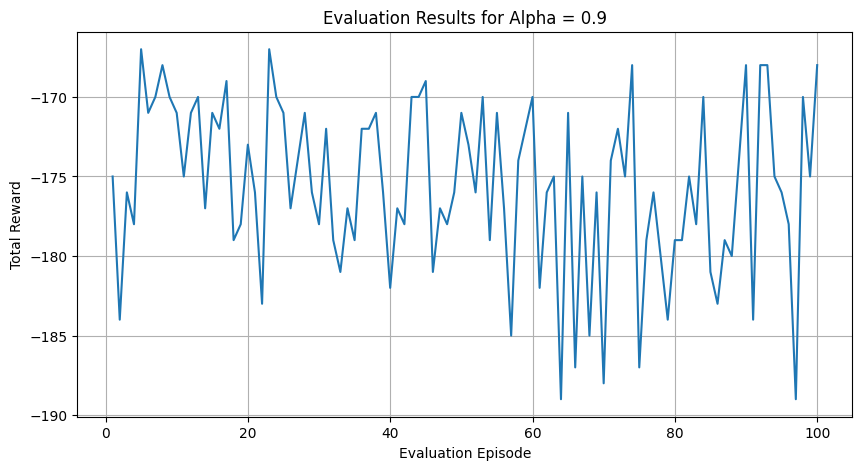

In [32]:
# Plot rewards from the 100 evaluation episodes
plt.figure(figsize=(10, 5))

plt.plot(
    range(1, 101),
    rewards_09
)

plt.xlabel("Evaluation Episode")
plt.ylabel("Total Reward")
plt.title("Evaluation Results for Alpha = 0.9")

plt.grid()
plt.show()

<br>
Alpha = 0.1 Training <br>
To compare the effect of the learning rate, I trained another agent using alpha = 0.1. All other seeting were kept the same as the alpha = 0.9 exercise.


In [33]:
# Create a new MountainCar environment
env_01 = gym.make("MountainCar-v0")

# Initialize a separate Q-table
q_01 = np.zeros((
    len(pos_space) + 1,
    len(vel_space) + 1,
    env_01.action_space.n
))

# Parameters
alpha_01 = 0.1
gamma = 0.9
epsilon_01 = 1.0
epsilon_decay = 2 / 5000

episodes = 5000

# Use the same random seed
rng_01 = np.random.default_rng(42)

rewards_train_01 = np.zeros(episodes)

for episode in range(episodes):

    # Reset environment
    state, _ = env_01.reset(seed=42 + episode)

    state_p = np.digitize(state[0], pos_space)
    state_v = np.digitize(state[1], vel_space)

    terminated = False
    truncated = False
    total_reward = 0

    while not terminated and not truncated:

        # Epsilon-greedy action selection
        if rng_01.random() < epsilon_01:
            action = int(
                rng_01.integers(
                    0, env_01.action_space.n
                )
            )
        else:
            action = int(
                np.argmax(q_01[state_p, state_v, :])
            )

        # Execute action
        new_state, reward, terminated, truncated, _ = env_01.step(
            action
        )

        # Discretize next state
        new_state_p = np.digitize(
            new_state[0], pos_space
        )
        new_state_v = np.digitize(
            new_state[1], vel_space
        )

        # Current Q-value
        current_q = q_01[state_p, state_v, action]

        # Q-learning target
        if terminated:
            target = reward
        else:
            max_next_q = np.max(
                q_01[new_state_p, new_state_v, :]
            )
            target = reward + gamma * max_next_q

        # Update Q-table
        q_01[state_p, state_v, action] = (
            current_q + alpha_01 * (target - current_q)
        )

        # Update state
        state_p = new_state_p
        state_v = new_state_v

        total_reward += reward

    rewards_train_01[episode] = total_reward

    # Reduce epsilon
    epsilon_01 = max(
        epsilon_01 - epsilon_decay, 0
    )

env_01.close()

print("Training completed for alpha = 0.1")
print("Total episodes:", episodes)
print("Q-table shape:", q_01.shape)
print(
    "Average training reward (last 100):",
    round(np.mean(rewards_train_01[-100:]), 2)
)


Training completed for alpha = 0.1
Total episodes: 5000
Q-table shape: (23, 23, 3)
Average training reward (last 100): -166.35


In [34]:
avg_reward_01, success_01, rewards_01 = evaluate_agent(q_01)

print("Evaluation for alpha = 0.1")
print("Average total reward:", avg_reward_01)
print("Goals reached:", success_01, "out of 100")
print("Success rate:", success_01, "%")

Evaluation for alpha = 0.1
Average total reward: -172.04
Goals reached: 86 out of 100
Success rate: 86 %


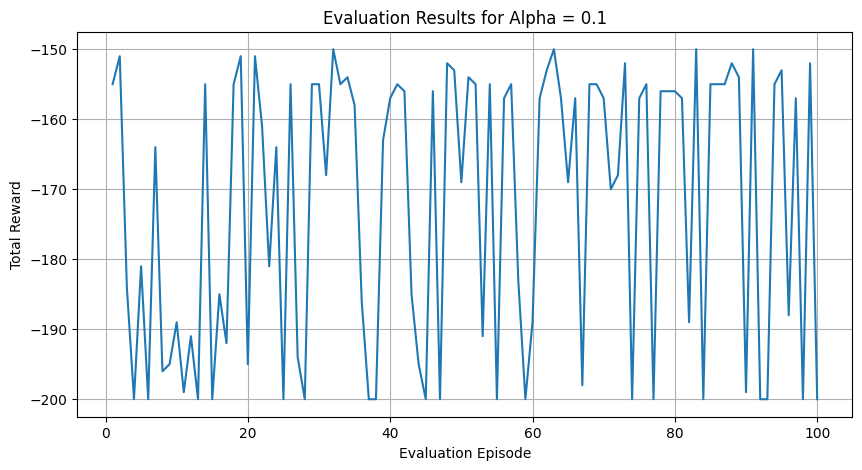

In [35]:
# Plot rewards from the 100 evaluation episodes for alpha = 0.1
plt.figure(figsize=(10, 5))

plt.plot(range(1, 101), rewards_01)

plt.xlabel("Evaluation Episode")
plt.ylabel("Total Reward")
plt.title("Evaluation Results for Alpha = 0.1")

plt.grid()
plt.show()

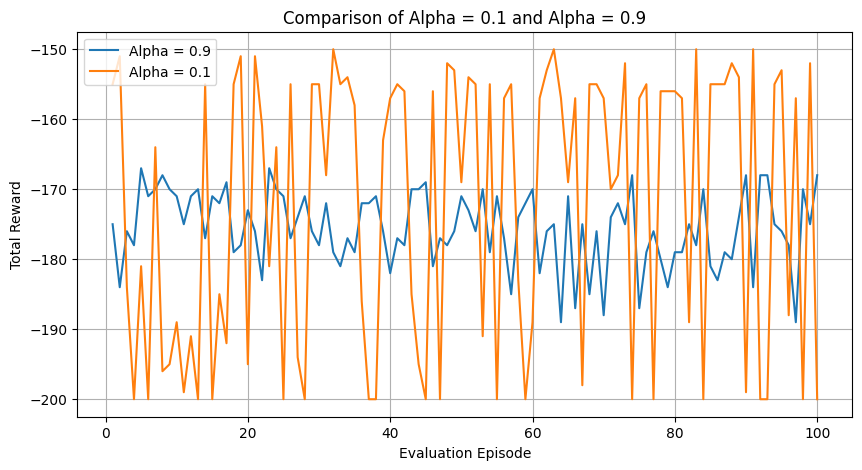

In [36]:
# Compare the evaluation rewards for both learning rates
plt.figure(figsize=(10, 5))

plt.plot(
    range(1, 101),
    rewards_09,
    label="Alpha = 0.9"
)

plt.plot(
    range(1, 101),
    rewards_01,
    label="Alpha = 0.1"
)

plt.xlabel("Evaluation Episode")
plt.ylabel("Total Reward")
plt.title("Comparison of Alpha = 0.1 and Alpha = 0.9")

plt.legend()
plt.grid()

plt.show()

In [37]:
print("Alpha = 0.9")
print("Average reward:", avg_reward_09)
print("Success rate:", success_09, "%")

print("\nAlpha = 0.1")
print("Average reward:", avg_reward_01)
print("Success rate:", success_01, "%")

Alpha = 0.9
Average reward: -175.59
Success rate: 100 %

Alpha = 0.1
Average reward: -172.04
Success rate: 86 %


In [38]:
import pandas as pd

results = pd.DataFrame({
    "Learning Rate": [0.1, 0.9],
    "Average Total Reward": [avg_reward_01, avg_reward_09],
    "Successful Episodes": [success_01, success_09],
    "Success Rate": [
        f"{success_01}%",
        f"{success_09}%"
    ]
})

display(results)


,Learning Rate,Average Total Reward,Successful Episodes,Success Rate
0,0.1,-172.04,86,86%
1,0.9,-175.59,100,100%


2(d) - Explanation:

I tested both agents for 100 episodes with exploration turned off.

For alpha = 0.9 , the agents reached the goal in all 100 episodes with an average reward of -175.59
For alpha = 0.1, the agent reached the goal in 86 episodes with an average reward of - 172.04

From the above result, alpha = 0.1 sometimes gave better rewards, but the results were more inconsistent.
Alpha = 0.9 was more stable and reached the goal every time. So I found alpha = 0.9 more reliable.



#### Bonus Question - Q-Learning with continuous MountainCar

Bonus (a) Environment Setup: for this part, I will create the MoutainCarContinuous-v0 environment and display it's observation space, action space and initial state. And then I will comapre the continous action space with the discrete actions used in MountainCar-v0.

In [39]:
import gymnasium as gym
import numpy as np
import matplotlib.pyplot as plt

# Create the continuous MountainCar environment
env_cont = gym.make('MountainCarContinuous-v0')

# Reset the environment using a fixed seed
state_cont = env_cont.reset(seed=42)[0]

print("Observation space:")
print(env_cont.observation_space)

print("\nAction space:")
print(env_cont.action_space)

print("\nInitial state:")
print(f"[{state_cont[0]:.4f}, {state_cont[1]:.4f}]")

print("\nState values:")
print("Position range:",
      env_cont.observation_space.low[0],
      "to",
      env_cont.observation_space.high[0])

print("Velocity range:",
      env_cont.observation_space.low[1],
      "to",
      env_cont.observation_space.high[1])

print("\nAction range:")
print(env_cont.action_space.low[0],
      "to",
      env_cont.action_space.high[0])

env_cont.close()

Observation space:
Box([-1.2  -0.07], [0.6  0.07], (2,), float32)

Action space:
Box(-1.0, 1.0, (1,), float32)

Initial state:
[-0.4452, 0.0000]

State values:
Position range: -1.2 to 0.6
Velocity range: -0.07 to 0.07

Action range:
-1.0 to 1.0


Bonus (a) - Explanation:
MountainCarContinuous-v0 uses two state values: position and velocity.

Unlike MountainCar-v0, which has three fixed actions, this environment uses a continuous action between -1 and 1. Negative values push the car left and positive values push it right.

Since the state and action values are continuous, I need to discretize them before using tabular Q-learning.

<br>
Bonus (b) - state and Action Discretization:

For tabular Q-learning, I discretize the continuous position, velocity and action values.
For that I use 22 boundaries for position and velocity and 5 possible continuous action values.The Q-table stores one Q-value for every discrete state state-action combination.

In [40]:
# To create the continuous MountainCar environment
env_cont = gym.make('MountainCarContinuous-v0')

# Same state discretization used earlier
X = 2
num_boundaries = 20 + X

# Divide position and velocity into equally spaced boundaries
pos_space_cont = np.linspace(
    env_cont.observation_space.low[0],
    env_cont.observation_space.high[0],
    num_boundaries
)

vel_space_cont = np.linspace(
    env_cont.observation_space.low[1],
    env_cont.observation_space.high[1],
    num_boundaries
)

# Start with 5 discrete action values
act_divisions = 5

# Create lookup values between -1 and 1
act_lookup_space = np.linspace(
    env_cont.action_space.low[0],
    env_cont.action_space.high[0],
    act_divisions
)

# Q-table
# +1 is needed for all possible np.digitize state indices
q_cont = np.zeros(
    (
        len(pos_space_cont) + 1,
        len(vel_space_cont) + 1,
        len(act_lookup_space)
    )
)

print("Position discretization:")
print(pos_space_cont)

print("\nVelocity discretization:")
print(vel_space_cont)

print("\nAction discretization:")
print(act_lookup_space)

print("\nNumber of available actions:")
print(len(act_lookup_space))

print("\nQ-table shape:")
print(q_cont.shape)

print("\nTotal Q-table entries:")
print(q_cont.size)

env_cont.close()

Position discretization:
[-1.2        -1.1142857  -1.0285715  -0.94285715 -0.8571429  -0.7714286
 -0.6857143  -0.6        -0.51428574 -0.42857146 -0.34285718 -0.2571429
 -0.17142856 -0.08571434  0.          0.08571422  0.17142856  0.2571429
  0.34285712  0.42857146  0.5142857   0.6       ]

Velocity discretization:
[-0.07       -0.06333333 -0.05666666 -0.05       -0.04333333 -0.03666667
 -0.03       -0.02333333 -0.01666667 -0.01       -0.00333333  0.00333334
  0.01        0.01666667  0.02333333  0.03        0.03666667  0.04333334
  0.05        0.05666666  0.06333334  0.07      ]

Action discretization:
[-1.  -0.5  0.   0.5  1. ]

Number of available actions:
5

Q-table shape:
(23, 23, 5)

Total Q-table entries:
2645


Bonus (b) - Explanation:
I divided the position and velocity ranges into 22 boundaries and selected 5 action values between -1 and 1.

The Q-table has a shape of (23,23,5) with 2645 entries. Each action has an index, which is used to select the corresponding continous action value from act_lookup_space.

During exploration, the agent randomly selects an index instead of a continous value. This allows me to apply tabular Q-learning to the continous MoutainCar environmnet.
<br>

<br>
Bonus(c) – Training the Q-Learning Agent:

For this,I'll train the MountainCarContinuous-v0 agent using Q-learning for 5,000 episodes. I'll use the discretized states and actions from Bonus (b).

The agent selects actions using the epsilon-greedy method. During training, it updates its Q-values based on the rewards received and gradually reduces exploration. During traing I also record the reward and epsilon values to see how agent's performance and exploration changes.

In [41]:

import gymnasium as gym
import numpy as np
import matplotlib.pyplot as plt

# Training parameters
episodes = 5000
learning_rate = 0.1
discount_factor = 0.99
epsilon_start = 1.0
epsilon_decay = 0.999
epsilon_min = 0.05

# Function to train the Q-learning agent
def train_continuous_q(act_divisions):
    env = gym.make("MountainCarContinuous-v0")
    rng = np.random.default_rng(42)

    # Position and velocity discretization
    pos_space = np.linspace(
        env.observation_space.low[0],
        env.observation_space.high[0],
        22
    )

    vel_space = np.linspace(
        env.observation_space.low[1],
        env.observation_space.high[1],
        22
    )

    # Continuous action discretization
    act_lookup_space = np.linspace(
        env.action_space.low[0],
        env.action_space.high[0],
        act_divisions
    )

    # Initialize Q-table
    q_table = np.zeros((23, 23, act_divisions))

    epsilon = epsilon_start
    rewards = []
    successes = []
    epsilon_values = []

    for episode in range(episodes):

        # Reset environment
        state, _ = env.reset(seed=42 + episode)

        state_p = np.digitize(state[0], pos_space)
        state_v = np.digitize(state[1], vel_space)

        total_reward = 0
        done = False

        epsilon_values.append(epsilon)

        while not done:

            # Epsilon-greedy action selection
            if rng.random() < epsilon:
                action_index = int(
                    rng.integers(0, act_divisions)
                )
            else:
                action_index = int(
                    np.argmax(q_table[state_p, state_v, :])
                )

            # Convert action index to continuous action
            action = np.array(
                [act_lookup_space[action_index]],
                dtype=np.float32
            )

            # Execute action
            new_state, reward, terminated, truncated, _ = env.step(
                action
            )

            done = terminated or truncated

            # Discretize the new state
            new_p = np.digitize(new_state[0], pos_space)
            new_v = np.digitize(new_state[1], vel_space)

            # Q-learning update
            old_q = q_table[state_p, state_v, action_index]

            if done:
                target = reward
            else:
                target = reward + discount_factor * np.max(
                    q_table[new_p, new_v, :]
                )

            q_table[state_p, state_v, action_index] = (
                old_q + learning_rate * (target - old_q)
            )

            state_p = new_p
            state_v = new_v

            total_reward += reward

        # Store episode results
        rewards.append(total_reward)
        successes.append(int(terminated))

        # Reduce exploration
        epsilon = max(
            epsilon_min,
            epsilon * epsilon_decay
        )

        # Print progress every 500 episodes
        if (episode + 1) % 500 == 0:
            print(
                f"Episode {episode + 1}/{episodes}, "
                f"Average Reward: {np.mean(rewards[-100:]):.2f}, "
                f"Epsilon: {epsilon:.3f}"
            )

    env.close()

    return (
        q_table,
        np.array(rewards),
        np.array(successes),
        np.array(epsilon_values)
    )


# Train agent with 5 action divisions
q_cont, rewards_5, successes_5, epsilon_5 = train_continuous_q(5)

print("\nTraining completed!")
print("Total episodes:", len(rewards_5))
print("Q-table shape:", q_cont.shape)
print(
    "Average reward (last 100):",
    round(np.mean(rewards_5[-100:]), 2)
)
print(
    "Successful episodes (last 100):",
    int(np.sum(successes_5[-100:]))
)


Episode 500/5000, Average Reward: -31.70, Epsilon: 0.606
Episode 1000/5000, Average Reward: -19.35, Epsilon: 0.368
Episode 1500/5000, Average Reward: -11.83, Epsilon: 0.223
Episode 2000/5000, Average Reward: -7.08, Epsilon: 0.135
Episode 2500/5000, Average Reward: -4.40, Epsilon: 0.082
Episode 3000/5000, Average Reward: -2.58, Epsilon: 0.050
Episode 3500/5000, Average Reward: -2.49, Epsilon: 0.050
Episode 4000/5000, Average Reward: -2.53, Epsilon: 0.050
Episode 4500/5000, Average Reward: -2.48, Epsilon: 0.050
Episode 5000/5000, Average Reward: -2.53, Epsilon: 0.050

Training completed!
Total episodes: 5000
Q-table shape: (23, 23, 5)
Average reward (last 100): -2.53
Successful episodes (last 100): 0


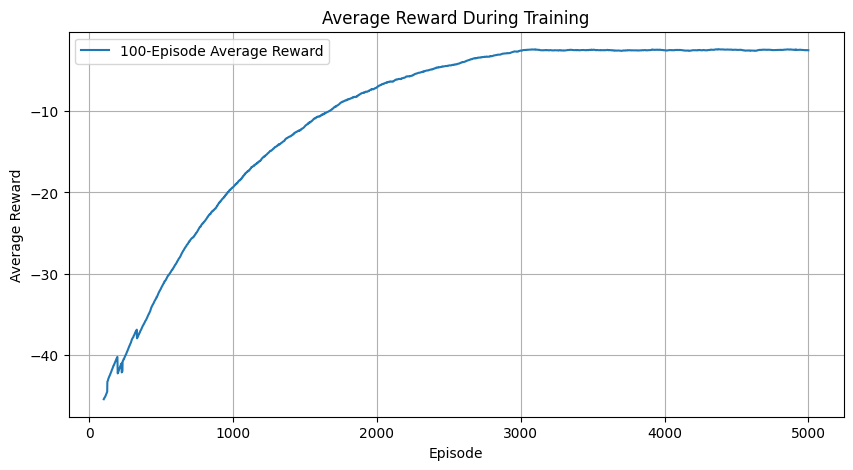

In [42]:
#Calculate the moving average of the last 100 episodes
window = 100

moving_avg_5 = np.convolve(
    rewards_5,
    np.ones(window) / window,
    mode="valid"
)

plt.figure(figsize=(10, 5))

plt.plot(
    np.arange(window, len(rewards_5) + 1),
    moving_avg_5,
    label="100-Episode Average Reward"
)

plt.title("Average Reward During Training")
plt.xlabel("Episode")
plt.ylabel("Average Reward")
plt.legend()
plt.grid(True)
plt.show()


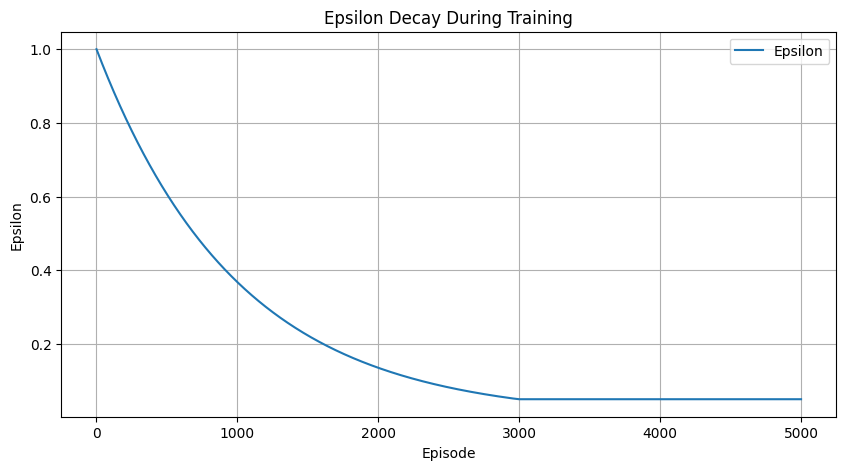

In [43]:
# Plot epsilon values over 5000 episodes
plt.figure(figsize=(10, 5))

plt.plot(
    np.arange(1, len(epsilon_5) + 1),
    epsilon_5,
    label="Epsilon"
)

plt.title("Epsilon Decay During Training")
plt.xlabel("Episode")
plt.ylabel("Epsilon")
plt.legend()
plt.grid(True)
plt.show()


Bonus (c) – Explanation:

I trained the agent for 5,000 episodes.The average reward improved from -31.70 to -2.53, showing that the rewards got better during training. Epsilon gradually decreased to 0.05, so the agent explored less. But, it did not reach the goal in the last 100 training episodes.

<br>
Bonus (d) - Comparing Different Action Divisions:

For this, I'll compare agent's performance using 5 and 10 divisons.And tested both trained agents for 100 episodes without exploration,then comapred their rewards and success rate.


In [44]:

# Train with 10 action divisions
q_cont_10, rewards_10, successes_10, epsilon_10 = train_continuous_q(10)

print("\nTraining completed for 10 action divisions!")
print("Q-table shape:", q_cont_10.shape)
print("Total Q-table entries:", q_cont_10.size)


Episode 500/5000, Average Reward: -26.24, Epsilon: 0.606
Episode 1000/5000, Average Reward: -16.56, Epsilon: 0.368
Episode 1500/5000, Average Reward: -10.60, Epsilon: 0.223
Episode 2000/5000, Average Reward: -6.88, Epsilon: 0.135
Episode 2500/5000, Average Reward: -4.78, Epsilon: 0.082
Episode 3000/5000, Average Reward: -3.30, Epsilon: 0.050
Episode 3500/5000, Average Reward: -3.21, Epsilon: 0.050
Episode 4000/5000, Average Reward: -3.24, Epsilon: 0.050
Episode 4500/5000, Average Reward: -3.22, Epsilon: 0.050
Episode 5000/5000, Average Reward: -3.30, Epsilon: 0.050

Training completed for 10 action divisions!
Q-table shape: (23, 23, 10)
Total Q-table entries: 5290


In [45]:

# Evaluate a trained agent without exploration or learning
def evaluate_continuous_q(q_table, act_divisions):
    env = gym.make("MountainCarContinuous-v0")

    pos_space = np.linspace(
        env.observation_space.low[0],
        env.observation_space.high[0],
        22
    )

    vel_space = np.linspace(
        env.observation_space.low[1],
        env.observation_space.high[1],
        22
    )

    act_lookup_space = np.linspace(
        env.action_space.low[0],
        env.action_space.high[0],
        act_divisions
    )

    evaluation_rewards = []
    successful_episodes = 0

    for episode in range(100):
        # Same seeds for both comparisons
        state, _ = env.reset(seed=10000 + episode)

        done = False
        total_reward = 0

        while not done:
            state_p = np.digitize(state[0], pos_space)
            state_v = np.digitize(state[1], vel_space)

            # Greedy action: exploration disabled
            action_index = int(
                np.argmax(q_table[state_p, state_v, :])
            )

            # Convert the action index to a continuous value
            action = np.array(
                [act_lookup_space[action_index]],
                dtype=np.float32
            )

            state, reward, terminated, truncated, _ = env.step(action)

            total_reward += reward
            done = terminated or truncated

            if terminated:
                successful_episodes += 1

        evaluation_rewards.append(total_reward)

    env.close()

    average_reward = np.mean(evaluation_rewards)
    success_rate = (successful_episodes / 100) * 100

    return average_reward, successful_episodes, success_rate


# Evaluate both trained agents
avg_5, success_5, rate_5 = evaluate_continuous_q(q_cont, 5)

avg_10, success_10, rate_10 = evaluate_continuous_q(q_cont_10, 10)

print("Evaluation episodes: 100")
print("Exploration: Disabled")
print("Q-table updates: Disabled")

print("\n5 Action Divisions:")
print("Average reward:", round(avg_5, 2))
print("Successful episodes:", success_5)
print("Success rate:", f"{rate_5:.1f}%")

print("\n10 Action Divisions:")
print("Average reward:", round(avg_10, 2))
print("Successful episodes:", success_10)
print("Success rate:", f"{rate_10:.1f}%")


Evaluation episodes: 100
Exploration: Disabled
Q-table updates: Disabled

5 Action Divisions:
Average reward: 0.0
Successful episodes: 0
Success rate: 0.0%

10 Action Divisions:
Average reward: -1.26
Successful episodes: 0
Success rate: 0.0%


In [46]:

import pandas as pd

# Compare evaluation results
bonus_d_results = pd.DataFrame({
    "Action Divisions": [5, 10],
    "Available Actions": [5, 10],
    "Q-table Size": [q_cont.size, q_cont_10.size],
    "Average Evaluation Reward": [
        round(avg_5, 2),
        round(avg_10, 2)
    ],
    "Successful Episodes": [
        f"{success_5}/100",
        f"{success_10}/100"
    ],
    "Success Rate": [
        f"{rate_5:.1f}%",
        f"{rate_10:.1f}%"
    ]
})

display(bonus_d_results)


,Action Divisions,Available Actions,Q-table Size,Average Evaluation Reward,Successful Episodes,Success Rate
0,5,5,2645,0.00,0/100,0.0%
1,10,10,5290,-1.26,0/100,0.0%


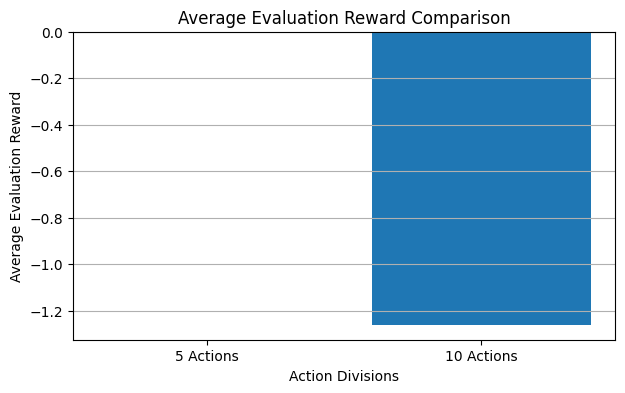

In [47]:
# Compare average evaluation rewards
plt.figure(figsize=(7, 4))

plt.bar(
    ["5 Actions", "10 Actions"],
    [avg_5, avg_10]
)

plt.title("Average Evaluation Reward Comparison")
plt.xlabel("Action Divisions")
plt.ylabel("Average Evaluation Reward")
plt.grid(axis="y")
plt.show()


<br>Bonus (d) - Explanation for 5 and 10 Action divisions comaprison:<br>
I tested both agents for 100 episodes without exploration or learning. With 5 actions,the average reward was 0.00 and with 10 actions, it was -1.26. Both agents failed to reach the goal. From this, I noticed that having more actions did not help the agent perform better.